# Extended sequential comparison

Paper §4.4: Greedy, VND + Beam, Uniform and Random.


In [11]:
# Resolve the project whether Jupyter starts here or from the repository root.
import importlib
from pathlib import Path
import sys
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

working = Path.cwd().resolve()
PROJECT = working / "problem-2-min-error-seq" if (working / "problem-2-min-error-seq").is_dir() else working
SOURCE = PROJECT / "src"
if str(SOURCE) not in sys.path:
    sys.path.insert(0, str(SOURCE))

_analysis_module = importlib.reload(importlib.import_module("analysis"))
run_analysis = _analysis_module.run_analysis
_figures_module = importlib.reload(importlib.import_module("figures"))
summary_markdown = _figures_module.summary_markdown
load_summary = _figures_module.load_summary
load_case_rows = _figures_module.load_case_rows


## Configuration

Choose test/full mode. `RUN_ANALYSIS=False` loads saved results; `True` evaluates cases, with matching checkpoint reuse controlled by `RESUME`.


In [ ]:
# Load saved results by default. Set this to True to run or resume the study.
RUN_ANALYSIS = False

# Use "full" for the complete study after confirming the test run.
RUN_MODE = "full"
RESUME = True
TIME_LIMIT_SECONDS = None

# These controls apply only to the heuristic method.
BEAM_WIDTH = 3
MAX_ITERATIONS = 30

# This notebook is intentionally tied to the extended datasets.
STUDY = "extended"

## Matched results


In [13]:
# Load saved tables unless an algorithm run is explicitly requested.
if RUN_ANALYSIS:
    run_analysis = importlib.reload(importlib.import_module("analysis")).run_analysis
    analysis = run_analysis(
        project=PROJECT,
        study=STUDY,
        mode=RUN_MODE,
        resume=RESUME,
        exact_k_max=4,
        time_limit=TIME_LIMIT_SECONDS,
        beam_width=BEAM_WIDTH,
        max_iterations=MAX_ITERATIONS,
    )
    print("Analysis run requested; algorithms were run or resumed.")
else:
    result_output = PROJECT / "results" / STUDY / RUN_MODE
    try:
        saved_summary = load_summary(PROJECT, STUDY, mode=RUN_MODE)
        saved_rows = load_case_rows(PROJECT, STUDY, mode=RUN_MODE)
    except FileNotFoundError as error:
        raise FileNotFoundError(
            f"Saved {STUDY} {RUN_MODE} results are unavailable. "
            "Set RUN_ANALYSIS = True to generate them."
        ) from error
    analysis = {
        "summary": saved_summary,
        "rows": saved_rows,
        "output": result_output,
    }
    print("Loaded saved results; no allocation algorithms were run.")

# Confirm that this notebook used both extended datasets and the four scalable methods.
expected_datasets = {"benchmark_1d", "benchmark_2d"}
expected_methods = {"Greedy", "Heuristic", "Uniform", "Random"}
observed_datasets = {row["dataset"] for row in analysis["rows"]}
observed_methods = {row["method"] for row in analysis["rows"]}
assert observed_datasets == expected_datasets
assert observed_methods == expected_methods
expected_k = set(range(3, 11))
expected_m = set(range(2, 11))
assert {int(row["K"]) for row in analysis["rows"]} == expected_k
assert {int(row["M"]) for row in analysis["rows"]} == expected_m
assert {(int(row["K"]), int(row["M"])) for row in analysis["rows"]} == {(K, M) for K in expected_k for M in expected_m}

case_counts = {
    dimension: len({
        (row["dataset"], row["case"])
        for row in analysis["rows"]
        if int(row["dimension"]) == dimension
    })
    for dimension in (1, 2)
}
if RUN_MODE == "test":
    assert min(case_counts.values()) >= 180

print("Verified datasets:", sorted(observed_datasets))
print("Verified methods:", sorted(observed_methods))
print("Unique cases by dimension:", case_counts)
print("Results directory:", analysis["output"])

extended/full: 4320 cases, methods: Greedy, Heuristic, Uniform, Random
No time limit per method/budget.
benchmark_1d: completed case 1/2160 (gaussian, K=3, M=2)
benchmark_1d: completed case 2/2160 (gaussian, K=3, M=2)
benchmark_1d: completed case 3/2160 (gaussian, K=3, M=2)
benchmark_1d: completed case 4/2160 (gaussian, K=3, M=2)
benchmark_1d: completed case 5/2160 (gaussian, K=3, M=2)
benchmark_1d: completed case 6/2160 (gaussian, K=3, M=2)
benchmark_1d: completed case 7/2160 (gaussian, K=3, M=2)
benchmark_1d: completed case 8/2160 (gaussian, K=3, M=2)
benchmark_1d: completed case 9/2160 (gaussian, K=3, M=2)
benchmark_1d: completed case 10/2160 (gaussian, K=3, M=2)
benchmark_1d: completed case 11/2160 (gaussian, K=3, M=3)
benchmark_1d: completed case 12/2160 (gaussian, K=3, M=3)
benchmark_1d: completed case 13/2160 (gaussian, K=3, M=3)
benchmark_1d: completed case 14/2160 (gaussian, K=3, M=3)
benchmark_1d: completed case 15/2160 (gaussian, K=3, M=3)
benchmark_1d: completed case 16/216

## Completion summary


In [14]:
# Report method completion before displaying aggregate values.
from collections import Counter

completion = Counter((row["method"], row["status"]) for row in analysis["rows"])
print("Method-status counts:", completion)
display(Markdown(summary_markdown(analysis["summary"])))

Method-status counts: Counter({('Greedy', 'ok'): 17218, ('Heuristic', 'ok'): 17218, ('Uniform', 'ok'): 17218, ('Random', 'ok'): 17218})


| Dimension | Budget | Method | Cases | Mean Error Probability | Mean Time (s) | Mean Gap |
|---|---:|---|---:|---:|---:|---:|
| One-dimensional | 1 | Greedy | 2160 | 0.46488 | 0.0103 | — |
| One-dimensional | 1 | Heuristic | 2160 | 0.26794 | 0.8330 | — |
| One-dimensional | 1 | Random | 2160 | 0.62510 | 0.0063 | — |
| One-dimensional | 1 | Uniform | 2160 | 0.64483 | 0.0063 | — |
| One-dimensional | 2 | Greedy | 2160 | 0.32953 | 0.0125 | — |
| One-dimensional | 2 | Heuristic | 2160 | 0.11016 | 0.8517 | — |
| One-dimensional | 2 | Random | 2160 | 0.54814 | 0.0064 | — |
| One-dimensional | 2 | Uniform | 2160 | 0.56319 | 0.0064 | — |
| One-dimensional | 3 | Greedy | 2155 | 0.23538 | 0.0145 | — |
| One-dimensional | 3 | Heuristic | 2155 | 0.03751 | 0.8871 | — |
| One-dimensional | 3 | Random | 2155 | 0.48572 | 0.0064 | — |
| One-dimensional | 3 | Uniform | 2155 | 0.49120 | 0.0064 | — |
| One-dimensional | 4 | Greedy | 2133 | 0.17869 | 0.0164 | — |
| One-dimensional | 4 | Heuristic | 2133 | 0.01584 | 0.9111 | — |
| One-dimensional | 4 | Random | 2133 | 0.44372 | 0.0065 | — |
| One-dimensional | 4 | Uniform | 2133 | 0.44105 | 0.0065 | — |
| Two-dimensional | 1 | Greedy | 2160 | 0.46113 | 0.0096 | — |
| Two-dimensional | 1 | Heuristic | 2160 | 0.29708 | 0.8602 | — |
| Two-dimensional | 1 | Random | 2160 | 0.64256 | 0.0060 | — |
| Two-dimensional | 1 | Uniform | 2160 | 0.66206 | 0.0060 | — |
| Two-dimensional | 2 | Greedy | 2160 | 0.32654 | 0.0118 | — |
| Two-dimensional | 2 | Heuristic | 2160 | 0.13200 | 0.7884 | — |
| Two-dimensional | 2 | Random | 2160 | 0.57997 | 0.0060 | — |
| Two-dimensional | 2 | Uniform | 2160 | 0.59104 | 0.0060 | — |
| Two-dimensional | 3 | Greedy | 2156 | 0.22778 | 0.0139 | — |
| Two-dimensional | 3 | Heuristic | 2156 | 0.05051 | 0.8353 | — |
| Two-dimensional | 3 | Random | 2156 | 0.52336 | 0.0061 | — |
| Two-dimensional | 3 | Uniform | 2156 | 0.52971 | 0.0061 | — |
| Two-dimensional | 4 | Greedy | 2134 | 0.16617 | 0.0158 | — |
| Two-dimensional | 4 | Heuristic | 2134 | 0.02434 | 0.8004 | — |
| Two-dimensional | 4 | Random | 2134 | 0.48281 | 0.0062 | — |
| Two-dimensional | 4 | Uniform | 2134 | 0.48276 | 0.0061 | — |

## Mean runtime


In [15]:
from collections import defaultdict
from statistics import fmean

def mean_runtime_table(rows):
    matched = _figures_module._matched_rows(rows)
    methods = [
        method for method in _figures_module.STYLES
        if any(row["method"] == method for row in matched)
    ]
    grouped = defaultdict(list)
    for row in matched:
        grouped[(int(row["dimension"]), int(row["K"]), row["method"])].append(
            float(row["seconds"])
        )

    table = []
    for dimension in (1, 2):
        K_values = sorted({
            int(row["K"]) for row in matched
            if int(row["dimension"]) == dimension
        })
        for K in K_values:
            row = {"dimension": dimension, "K": K}
            counts = []
            for method in methods:
                values = grouped[(dimension, K, method)]
                row[f"{method.lower()}_mean_seconds"] = fmean(values)
                counts.append(len(values))
            if len(set(counts)) != 1:
                raise RuntimeError(
                    f"Runtime comparison is not matched for dimension={dimension}, K={K}"
                )
            row["runs_per_method"] = counts[0]
            table.append(row)
    return table, methods


def runtime_markdown(rows, methods):
    headings = ["Dimension", "K", "Runs per method", *methods]
    lines = [
        "| " + " | ".join(headings) + " |",
        "|" + "|".join("---:" for _ in headings) + "|",
    ]
    for row in rows:
        values = [f"{row['dimension']}D", str(row["K"]), str(row["runs_per_method"])]
        values.extend(
            f"{row[f'{method.lower()}_mean_seconds']:.5f}"
            for method in methods
        )
        lines.append("| " + " | ".join(values) + " |")
    return "\n".join(lines)


runtime_rows, runtime_methods = mean_runtime_table(analysis["rows"])
_analysis_module.write_csv(
    analysis["output"] / "tables" / "mean_runtime.csv",
    runtime_rows,
)
display(Markdown(runtime_markdown(runtime_rows, runtime_methods)))

| Dimension | K | Runs per method | Greedy | Heuristic | Uniform | Random |
|---:|---:|---:|---:|---:|---:|---:|
| 1D | 3 | 1048 | 0.00039 | 0.00216 | 0.00012 | 0.00011 |
| 1D | 4 | 1080 | 0.00105 | 0.00699 | 0.00025 | 0.00025 |
| 1D | 5 | 1080 | 0.00228 | 0.02143 | 0.00056 | 0.00055 |
| 1D | 6 | 1080 | 0.00432 | 0.03676 | 0.00121 | 0.00120 |
| 1D | 7 | 1080 | 0.00806 | 0.09264 | 0.00264 | 0.00263 |
| 1D | 8 | 1080 | 0.01416 | 0.29652 | 0.00574 | 0.00572 |
| 1D | 9 | 1080 | 0.02630 | 1.21205 | 0.01263 | 0.01280 |
| 1D | 10 | 1080 | 0.05036 | 5.27047 | 0.02775 | 0.02773 |
| 2D | 3 | 1050 | 0.00043 | 0.00237 | 0.00012 | 0.00011 |
| 2D | 4 | 1080 | 0.00116 | 0.00805 | 0.00026 | 0.00026 |
| 2D | 5 | 1080 | 0.00249 | 0.02895 | 0.00056 | 0.00055 |
| 2D | 6 | 1080 | 0.00468 | 0.04035 | 0.00122 | 0.00122 |
| 2D | 7 | 1080 | 0.00829 | 0.09652 | 0.00268 | 0.00266 |
| 2D | 8 | 1080 | 0.01455 | 0.29988 | 0.00576 | 0.00574 |
| 2D | 9 | 1080 | 0.02613 | 1.19857 | 0.01251 | 0.01271 |
| 2D | 10 | 1080 | 0.04392 | 4.87145 | 0.02523 | 0.02516 |

## Allocation and error comparisons

Family error intervals are instance-level 95% confidence intervals.


### Error Probability

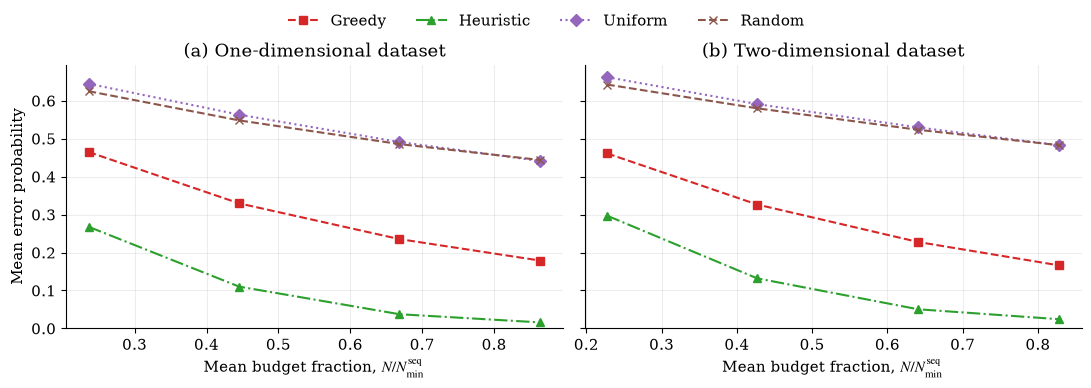

### Allocation Match

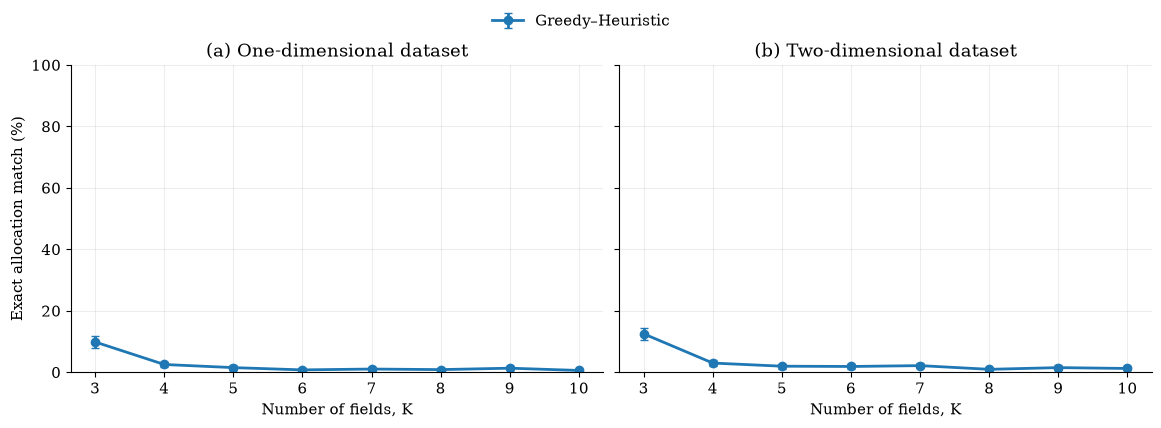

### Error By Field Family

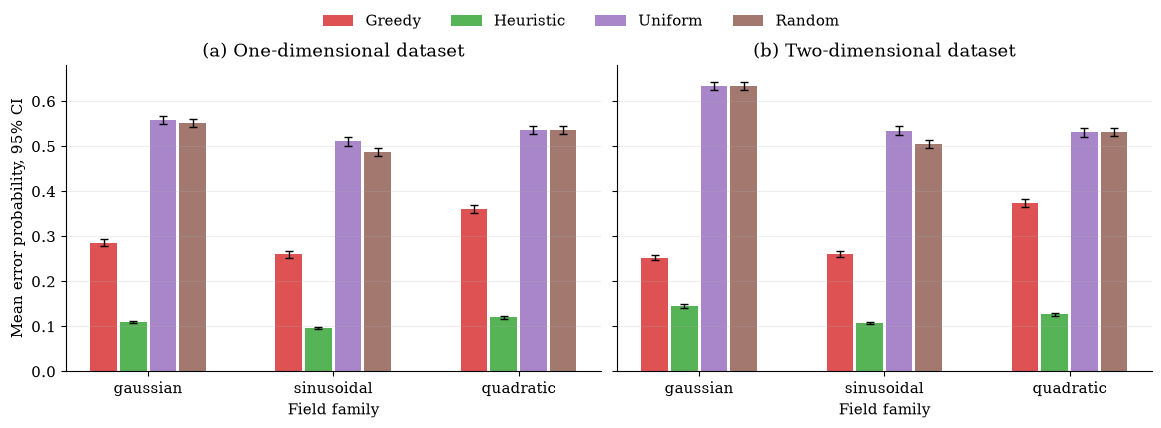

In [16]:
# Save and display the requested figures. Runtime is table-only.
from collections import defaultdict
from statistics import fmean
_figures_module = importlib.reload(importlib.import_module("figures"))


def instance_averaged_error_rows(rows):
    grouped = defaultdict(list)
    metadata = {}
    for row in _figures_module._matched_rows(rows):
        key = (row["dataset"], row["case"], row["method"])
        grouped[key].append(_figures_module._error(row))
        metadata[key] = row

    averaged = []
    for key, values in grouped.items():
        row = dict(metadata[key])
        mean_error = fmean(values)
        row["N"] = 0
        row["actual_error"] = mean_error
        row["error_probability"] = mean_error
        averaged.append(row)
    return averaged

if not analysis["summary"]:
    raise RuntimeError("No matched completed cases are available for plotting")

figures = {
    "error_probability": _figures_module.plot_mean_error(analysis["summary"]),
    "allocation_match": _figures_module.plot_allocation_match(analysis["rows"]),
    "error_by_field_family": _figures_module.plot_error_by_family(
        instance_averaged_error_rows(analysis["rows"])
    ),
}
figure_directory = analysis["output"] / "figures"
figure_directory.mkdir(parents=True, exist_ok=True)
for obsolete_name in ("runtime_by_k", "runtime_boxplot", "seconds"):
    for extension in ("pdf", "png"):
        (figure_directory / f"{obsolete_name}.{extension}").unlink(missing_ok=True)
for name, figure in figures.items():
    for extension in ("pdf", "png"):
        figure.savefig(
            figure_directory / f"{name}.{extension}",
            dpi=300,
            bbox_inches="tight",
        )
    display(Markdown(f"### {name.replace('_', ' ').title()}"))
    display(figure)
    plt.close(figure)


## VND iterations

One iteration is one neighborhood scan; each observation is an instance–budget evaluation.


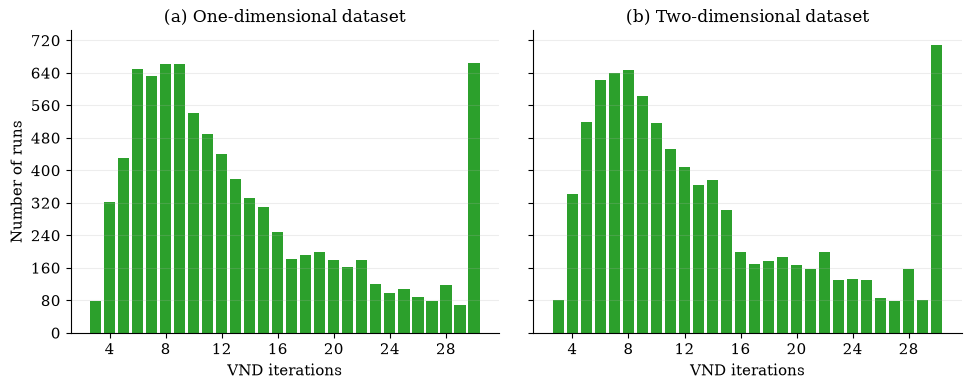

In [17]:
_figures_module = importlib.reload(importlib.import_module("figures"))
iteration_rows = _figures_module.iteration_summary(analysis["rows"])
if any(row["missing_diagnostics"] or not row["recorded"] for row in iteration_rows):
    print("Saved results lack complete iteration diagnostics. Run this analysis with the updated code first.")
else:
    iteration_figure = _figures_module.plot_iterations(analysis["rows"])
    output = Path(analysis["output"])
    (output / "figures").mkdir(parents=True, exist_ok=True)
    for extension in ("pdf", "png"):
        iteration_figure.savefig(output / "figures" / f"vnd_iterations.{extension}",
                                 dpi=300, bbox_inches="tight")
    display(iteration_figure)
    plt.close(iteration_figure)
